# **03 - Pilot Evaluation Pipeline**

## **1. Pipeline Objective**

## **2. Dependency Management**

### **2.1 Package Installation**

In [1]:
!pip install -q transformers accelerate bitsandbytes pandas matplotlib seaborn

### **2.2 Module Imports**

In [2]:
import datetime
import json
import os
import gc
import re
import time

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

### **2.3 Environment Variables**

In [3]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = "Qwen/Qwen3-4B-Instruct-2507"

os.environ['HF_HOME'] = MODELS_DIR

print(f"[MODEL] id='{MODEL_ID}' | status=CONFIGURING")

[MODEL] id='Qwen/Qwen3-4B-Instruct-2507' | status=CONFIGURING


## **3. Resource Allocation**

### **3.1 Identity & Access Management (IAM)**

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    secrets_path = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN")
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'


In [ ]:
for d in [DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

## **4. Prompt Generator Node**

In [6]:
pilot_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
df_pilot = pd.read_parquet(pilot_path)
print(f"[DATASET] split='pilot' | samples={len(df_pilot)} | status=LOADED")

[DATASET] split='pilot' | samples=150 | status=LOADED


## **5. LLM Initialization (Quantized)**

In [7]:
def format_prompt(input_text: str, resp_A: str, resp_B: str, p_id: str) -> str:
    if p_id == "P1":
        return (
            f"### TUGAS\nBandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nKeluarkan HANYA satu huruf: A atau B. Dilarang menulis alasan atau teks lain."
        )
    elif p_id == "P2":
        return (
            f"### TUGAS\nNilai dua respons AI berikut berdasarkan: Akurasi (kebenaran), Relevansi (menjawab instruksi), dan Kejelasan (tidak bertele-tele).\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nBerdasarkan kriteria di atas, keluarkan HANYA satu huruf: A atau B. Dilarang memberikan penjelasan."
        )
    elif p_id == "P3":
        return (
            f"### TUGAS\nTentukan respons terbaik untuk instruksi di bawah ini.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### ATURAN KETAT\n- Abaikan urutan kemunculan respons (jangan bias posisi).\n- Abaikan panjang respons (jangan bias verbosity).\n- FORMAT JAWABAN WAJIB: Keluarkan hanya karakter A atau B."
        )
    return ""

def apply_chat_template(tokenizer, text: str) -> str:
    messages = [
        {"role": "system", "content": "Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat."},
        {"role": "user", "content": text}
    ]
    return tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True
    )

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, cache_dir=MODELS_DIR)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    cache_dir=MODELS_DIR
)
allocated_vram = torch.cuda.memory_allocated() / 1024**3
print(f"[MODEL] status=LOADED | vram='{allocated_vram:.2f} GB'")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[MODEL] status=LOADED | vram='2.49 GB'


## **6. Symmetrical Execution Engine**

### **6.1 State Inspection (Idempotency Check)**

In [9]:
pilot_results_path = os.path.join(RESULTS_DIR, 'pilot_outputs.jsonl')

processed_combinations = set()
if os.path.exists(pilot_results_path):
    with open(pilot_results_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                unique_key = (data['sample_id'], data['prompt_id'], data['position'])
                processed_combinations.add(unique_key)

print(f"[RESUME] processed={len(processed_combinations)} | status=ACTIVE")

[RESUME] processed=900 | status=ACTIVE


### **6.2 Compute Loop**

In [10]:
class InferenceTelemetry:
    def __init__(self, total_steps, log_interval=10):
        self.total_steps = total_steps
        self.log_interval = log_interval
        self.current_step = 0
        self.start_time = time.time()

    def update(self, step_size=1, **kwargs):
        self.current_step += step_size
        if self.current_step % self.log_interval == 0 or self.current_step == self.total_steps:
            now = time.time()
            elapsed = now - self.start_time
            avg_time = elapsed / self.current_step if self.current_step > 0 else 0
            eta_seconds = (self.total_steps - self.current_step) * avg_time
            
            eta_str = str(datetime.timedelta(seconds=int(eta_seconds)))
            pct = (self.current_step / self.total_steps) * 100
            
            metrics = " | ".join([f"{k}: {v}" for k, v in kwargs.items()])
            metrics_str = f" | {metrics}" if metrics else ""
                
            print(f"[TELEMETRY] Step: {self.current_step}/{self.total_steps} ({pct:.1f}%) | ETA: {eta_str}{metrics_str}")

In [11]:
prompts = ["P1", "P2", "P3"]
positions = ["AB", "BA"]
total_iterations = len(df_pilot) * len(prompts) * len(positions)

print(
    f"[INFERENCE] total_iterations={total_iterations} | "
    f"status=STARTED"
)

telemetry = InferenceTelemetry(total_steps=total_iterations, log_interval=10)
if len(processed_combinations) > 0:
    telemetry.update(step_size=len(processed_combinations))

with torch.inference_mode():
    for index, row in df_pilot.iterrows():
        sample_id = int(row['original_id'])
        input_text = row['input']
        human_winner = "A" if row['chosen_model'] == row['response_1'] else "B"

        for p_id in prompts:
            for pos in positions:
                if (sample_id, p_id, pos) in processed_combinations:
                    continue

                if pos == "AB":
                    resp_A, resp_B = row['response_1'], row['response_2']
                    current_human = human_winner
                else:
                    resp_A, resp_B = row['response_2'], row['response_1']
                    current_human = "B" if human_winner == "A" else "A"

                start_time = time.time()
                raw_prompt = format_prompt(input_text, resp_A, resp_B, p_id)
                formatted_prompt = apply_chat_template(tokenizer, raw_prompt)

                inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)

                outputs = model.generate(
                    **inputs,
                    max_new_tokens=10,
                    do_sample=False,
                    pad_token_id=tokenizer.eos_token_id
                )

                input_len = inputs['input_ids'].shape[1]
                generated_tokens = outputs[0][input_len:]
                raw_output = tokenizer.decode(generated_tokens, skip_special_tokens=True)

                runtime = time.time() - start_time
                output_len = len(generated_tokens)
                tps = output_len / runtime if runtime > 0 else 0.0

                record = {
                    "sample_id": sample_id,
                    "domain": row['domain'],
                    "prompt_id": p_id,
                    "position": pos,
                    "human_preference": current_human,
                    "raw_output": raw_output,
                    "runtime_sec": round(runtime, 2),
                    "output_tokens": output_len,
                    "tps": round(tps, 2)
                }

                with open(pilot_results_path, 'a', encoding='utf-8') as f:
                    f.write(json.dumps(record) + '\n')

                processed_combinations.add((sample_id, p_id, pos))
                gen_time = time.time() - start_time
                tps = len(outputs[0]) / gen_time if gen_time > 0 else 0
                telemetry.update(
                    1, 
                    ID=row['original_id'], 
                    Cond=f"{p_id}_{pos}", 
                    Res=repr(raw_output), 
                    TPS=f"{tps:.1f}", 
                    Time=f"{gen_time:.1f}s"
                )

                del inputs, outputs
                torch.cuda.empty_cache()
                gc.collect()

[INFERENCE] total_iterations=900 | status=STARTED
[TELEMETRY] Step: 900/900 (100.0%) | ETA: 0:00:00


## **7. Performance Telemetry**

### **7.1 Semantic Extraction**

In [12]:
results = []
with open(pilot_results_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            results.append(json.loads(line))

df_res = pd.DataFrame(results)

def parse_decision(raw_output: str) -> str:
    clean_text: str = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

df_res['parsed_decision'] = df_res['raw_output'].apply(parse_decision)
df_res['is_match'] = df_res['parsed_decision'] == df_res['human_preference']

invalid_count = (df_res['parsed_decision'] == "INVALID").sum()
invalid_rate = (invalid_count / len(df_res)) * 100

print(
    f"[METRICS] total={len(df_res)} | "
    f"parse_failures={invalid_count} | "
    f"failure_rate={invalid_rate:.1f}%"
)
assert invalid_rate < 10.0, (
    "[INFERENCE] status=FAILED | "
    "error='parse_failure_rate_exceeded' | "
    f"actual={invalid_rate:.1f}% | "
    "threshold=10.0%"
)

[METRICS] total=900 | parse_failures=0 | failure_rate=0.0%


### **7.2 Position Bias Profiling**

In [13]:
df_valid = df_res[df_res['parsed_decision'] != "INVALID"].copy()
pos_dist = df_valid['parsed_decision'].value_counts(normalize=True) * 100

print(pos_dist)
if 'A' in pos_dist and pos_dist['A'] > 55:
    print("[ANALYSIS] metric='position_bias' | observation='A-dominant'")
elif 'B' in pos_dist and pos_dist['B'] > 55:
    print("[ANALYSIS] metric='position_bias' | observation='B-dominant'")
else:
    print("[ANALYSIS] metric='position_bias' | observation='balanced'")

parsed_decision
A    59.333333
B    40.666667
Name: proportion, dtype: float64
[ANALYSIS] metric='position_bias' | observation='A-dominant'


### **7.3 Prompt Sensitivity Profiling**

In [14]:
prompt_accuracy = df_valid.groupby('prompt_id')['is_match'].mean() * 100
print(prompt_accuracy)

prompt_id
P1    49.666667
P2    50.333333
P3    50.000000
Name: is_match, dtype: float64


### **7.4 Telemetry Dashboard**

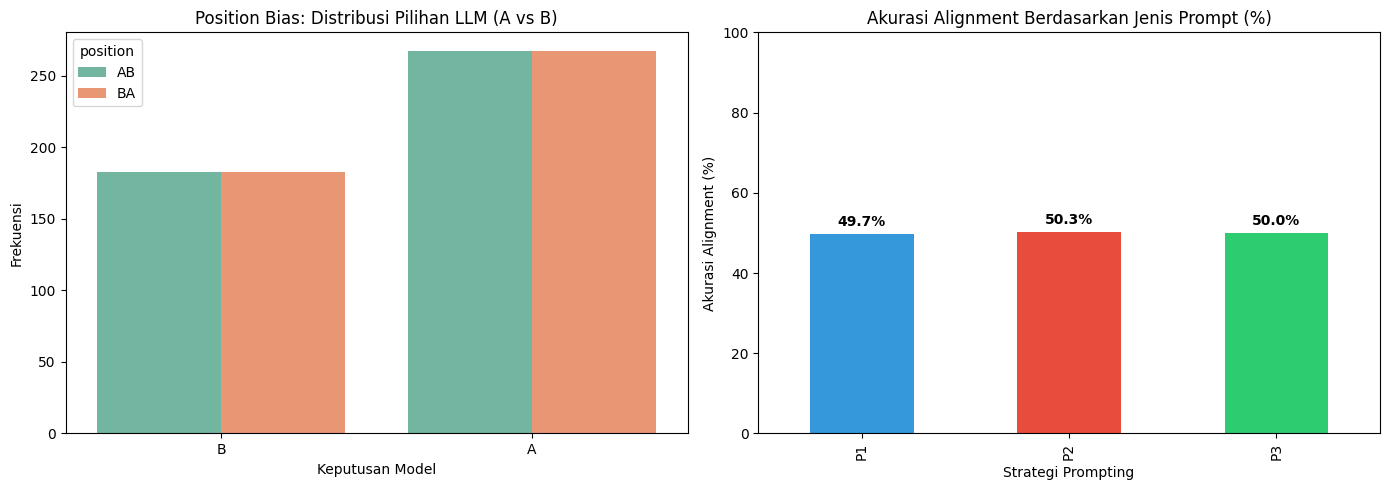

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_valid, x='parsed_decision', ax=axes[0], hue='position', palette='Set2')
axes[0].set_title('Position Bias: Distribusi Pilihan LLM (A vs B)')
axes[0].set_xlabel('Keputusan Model')
axes[0].set_ylabel('Frekuensi')

prompt_accuracy.plot(kind='bar', ax=axes[1], color=['#3498db', '#e74c3c', '#2ecc71'])
axes[1].set_title('Akurasi Alignment Berdasarkan Jenis Prompt (%)')
axes[1].set_xlabel('Strategi Prompting')
axes[1].set_ylabel('Akurasi Alignment (%)')
axes[1].set_ylim(0, 100)

for i, v in enumerate(prompt_accuracy):
    axes[1].text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()